In [77]:
# Library untuk pengolahan data numerik
import numpy as np
import pandas as pd

# Library untuk visualisasi data
import matplotlib.pyplot as plt
import seaborn as sns

# Mengambil dataset Breast Cancer dari Scikit-learn
from sklearn.datasets import load_breast_cancer

# Library untuk membagi dataset dan normalisasi data
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Library untuk membangun pipeline dan model klasifikasi
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression

# Library untuk evaluasi performa model
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    roc_auc_score
)

print("Semua librari berhasil dimasukkan")

Semua librari berhasil dimasukkan


In [78]:
# Memuat Breast Cancer Wisconsin Dataset
data = load_breast_cancer()

# Mengambil fitur dan mengubahnya menjadi DataFrame
X = pd.DataFrame(
    data.data,
    columns=data.feature_names
)

# Mengambil label atau target kelas
y = data.target

# Menampilkan dimensi dataset
print("Dataset Shape:", X.shape)

# Menampilkan lima sampel pertama
print("\nFirst 5 Samples:")
print(X.head())

# Menampilkan nama kelas target
print("\nTarget Classes:")
print(data.target_names)

Dataset Shape: (569, 30)

First 5 Samples:
   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dimension  ...  worst radius  wor

In [79]:
# Menampilkan informasi umum dataset
print("Dataset Information:")
print(X.info())

# Memeriksa jumlah missing values
print("\nMissing Values:")
print(X.isnull().sum().sum())

# Menampilkan statistik deskriptif
print("\nStatistical Description:")
print(X.describe())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 30 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoot

Class Distribution:
0    212
1    357
Name: count, dtype: int64


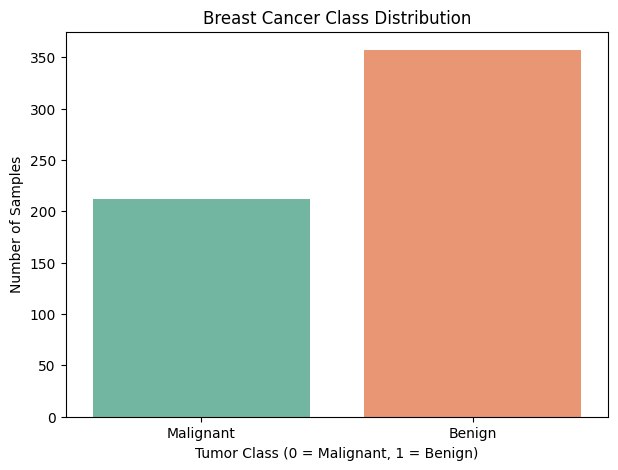

In [80]:
# Menghitung jumlah sampel pada setiap kelas
class_counts = pd.Series(y).value_counts().sort_index()

# Menampilkan jumlah sampel
print("Class Distribution:")
print(class_counts)

# Visualisasi distribusi kelas
plt.figure(figsize=(7, 5))

sns.countplot(
    x=y,
    hue=y,
    palette="Set2",
    legend=False
)

plt.title("Breast Cancer Class Distribution")
plt.xlabel("Tumor Class (0 = Malignant, 1 = Benign)")
plt.ylabel("Number of Samples")
plt.xticks([0, 1], ["Malignant", "Benign"])

plt.show()

In [81]:
# Membagi dataset menjadi training dan testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Menampilkan jumlah data
print("Training Samples:", X_train.shape[0])
print("Testing Samples:", X_test.shape[0])

print("\nTraining Features:", X_train.shape)
print("Testing Features:", X_test.shape)

Training Samples: 455
Testing Samples: 114

Training Features: (455, 30)
Testing Features: (114, 30)


In [82]:
# Membuat pipeline yang menggabungkan standardisasi dan Logistic Regression
model = make_pipeline(
    StandardScaler(),

    LogisticRegression(
        max_iter=1000,
        random_state=42
    )
)

# Melatih model menggunakan data training
model.fit(X_train, y_train)

print("Model Training Completed!")

Model Training Completed!


In [83]:
# Melakukan prediksi menggunakan data testing
y_pred = model.predict(X_test)

# Menampilkan hasil prediksi
print("Predicted Classes:")
print(y_pred)

# Menampilkan label sebenarnya
print("\nActual Classes:")
print(y_test)

Predicted Classes:
[0 1 0 1 0 1 1 0 0 0 1 0 1 0 0 1 0 1 1 1 0 0 1 1 1 1 0 1 1 1 1 1 1 1 0 0 1
 1 1 0 1 1 1 0 0 1 1 1 1 0 1 1 1 1 1 1 1 0 0 1 1 1 1 1 0 0 1 1 1 1 1 1 1 0
 0 0 0 1 1 1 1 1 0 1 0 1 1 1 1 1 1 1 0 0 0 1 0 1 0 1 0 0 0 1 0 0 1 0 1 0 1
 0 1 1]

Actual Classes:
[0 1 0 1 0 1 1 0 0 0 1 0 1 0 0 1 1 1 1 1 0 0 1 1 1 1 0 1 1 1 1 1 1 1 0 0 1
 1 1 0 1 1 1 0 0 1 1 1 1 0 1 1 1 0 1 1 1 0 0 1 1 1 1 1 0 0 1 1 1 1 1 1 1 0
 0 0 0 1 1 1 1 1 0 1 0 1 1 1 1 1 1 1 0 0 0 1 0 1 0 1 0 0 0 1 0 0 1 0 1 0 1
 0 1 1]


In [84]:
# Menghitung akurasi model
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", accuracy)

print("Model Accuracy (%):", accuracy * 100)

Model Accuracy: 0.9824561403508771
Model Accuracy (%): 98.24561403508771


In [85]:
# Menampilkan classification report
print("Classification Report:")

print(
    classification_report(
        y_test,
        y_pred,
        target_names=data.target_names
    )
)

Classification Report:
              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



In [86]:
# Mengambil probabilitas prediksi untuk kelas 1 (Benign)
y_probability = model.predict_proba(X_test)[:, 1]

# Menghitung nilai ROC-AUC
auc = roc_auc_score(y_test, y_probability)

print("ROC-AUC Score:", auc)

ROC-AUC Score: 0.9953703703703703


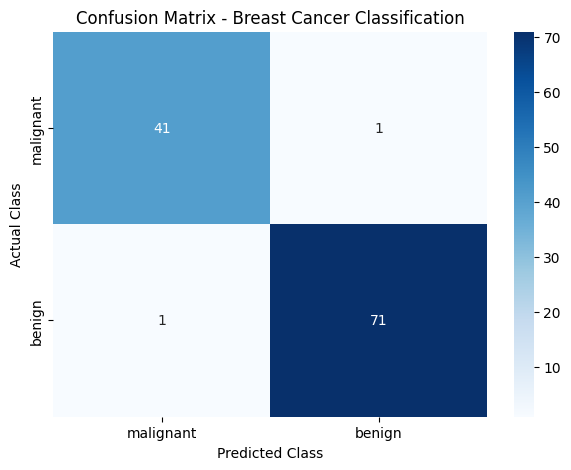

In [87]:
# Menghitung confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Visualisasi confusion matrix
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=data.target_names,
    yticklabels=data.target_names
)

plt.title("Confusion Matrix - Breast Cancer Classification")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.show()

In [88]:
sample = X_test.iloc[[0]]

# Menampilkan fitur sampel
print("Input Sample:")
print(sample)

# Melakukan prediksi
prediction = model.predict(sample)[0]

# Mengambil probabilitas prediksi
probability = model.predict_proba(sample)[0]

# Mengubah label numerik menjadi nama kelas
result = data.target_names[prediction]

# Menampilkan hasil prediksi
print("\nPrediction Result:", result)

print("\nPrediction Probability:")

for class_name, prob in zip(data.target_names, probability):

    print(
        class_name,
        ":",
        round(prob * 100, 2),
        "%"
    )

Input Sample:
     mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
256        19.55         28.77           133.6     1207.0           0.0926   

     mean compactness  mean concavity  mean concave points  mean symmetry  \
256            0.2063          0.1784               0.1144         0.1893   

     mean fractal dimension  ...  worst radius  worst texture  \
256                 0.06232  ...         25.05          36.27   

     worst perimeter  worst area  worst smoothness  worst compactness  \
256            178.6      1926.0            0.1281             0.5329   

     worst concavity  worst concave points  worst symmetry  \
256           0.4251                0.1941          0.2818   

     worst fractal dimension  
256                   0.1005  

[1 rows x 30 columns]

Prediction Result: malignant

Prediction Probability:
malignant : 100.0 %
benign : 0.0 %


In [89]:
# Library untuk pengolahan data dan visualisasi
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Dataset dan pembagian data
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

# Algoritma klasifikasi
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# Evaluasi model
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_auc_score
)

print("Semua library berhasil dimasukkan.")

Semua library berhasil dimasukkan.


In [90]:
# Memuat dataset Breast Cancer Wisconsin
data = load_breast_cancer()

X = pd.DataFrame(data.data, columns=data.feature_names)
y = data.target

print("Dataset shape:", X.shape)
print("Target classes:", data.target_names)
print("\nDistribusi kelas:")
print(pd.Series(y).value_counts().sort_index().rename(index={0: "malignant", 1: "benign"}))

Dataset shape: (569, 30)
Target classes: ['malignant' 'benign']

Distribusi kelas:
malignant    212
benign       357
Name: count, dtype: int64


In [91]:
# Memeriksa data
print("Jumlah missing values:", X.isnull().sum().sum())
display(X.head())

Jumlah missing values: 0


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [92]:
# Membagi dataset: 70% training dan 30% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    train_size=0.70,
    test_size=0.30,
    random_state=42,
    stratify=y
)

print("Jumlah data training:", X_train.shape[0])
print("Jumlah data testing:", X_test.shape[0])
print("Bentuk X_train:", X_train.shape)
print("Bentuk X_test:", X_test.shape)

Jumlah data training: 398
Jumlah data testing: 171
Bentuk X_train: (398, 30)
Bentuk X_test: (171, 30)


In [93]:
# Membuat dan melatih model Logistic Regression
logistic_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=10000, random_state=42)
)

logistic_model.fit(X_train, y_train)
y_pred_logistic = logistic_model.predict(X_test)

print("Pelatihan Logistic Regression selesai.")

Pelatihan Logistic Regression selesai.


In [94]:
# Membuat dan melatih model Random Forest
random_forest_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

random_forest_model.fit(X_train, y_train)
y_pred_rf = random_forest_model.predict(X_test)

print("Pelatihan Random Forest selesai.")

Pelatihan Random Forest selesai.


In [95]:
# Menghitung metrik dengan malignant (label 0) sebagai kelas positif
def hitung_metrik(y_true, y_pred, nama_model):
    return {
        "Algoritma": nama_model,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision (malignant)": precision_score(y_true, y_pred, pos_label=0, zero_division=0),
        "Recall (malignant)": recall_score(y_true, y_pred, pos_label=0, zero_division=0),
        "F1-score (malignant)": f1_score(y_true, y_pred, pos_label=0, zero_division=0)
    }

evaluation_results = pd.DataFrame([
    hitung_metrik(y_test, y_pred_logistic, "Logistic Regression"),
    hitung_metrik(y_test, y_pred_rf, "Random Forest")
])

display(evaluation_results.round(4))

,Algoritma,Accuracy,Precision (malignant),Recall (malignant),F1-score (malignant)
0,Logistic Regression,0.9883,0.9844,0.9844,0.9844
1,Random Forest,0.9357,0.9206,0.9062,0.9134


In [96]:
# Classification report lengkap untuk setiap kelas
print("LOGISTIC REGRESSION")
print(classification_report(
    y_test, y_pred_logistic,
    labels=[0, 1],
    target_names=["malignant", "benign"],
    zero_division=0
))

print("RANDOM FOREST")
print(classification_report(
    y_test, y_pred_rf,
    labels=[0, 1],
    target_names=["malignant", "benign"],
    zero_division=0
))

LOGISTIC REGRESSION
              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        64
      benign       0.99      0.99      0.99       107

    accuracy                           0.99       171
   macro avg       0.99      0.99      0.99       171
weighted avg       0.99      0.99      0.99       171

RANDOM FOREST
              precision    recall  f1-score   support

   malignant       0.92      0.91      0.91        64
      benign       0.94      0.95      0.95       107

    accuracy                           0.94       171
   macro avg       0.93      0.93      0.93       171
weighted avg       0.94      0.94      0.94       171



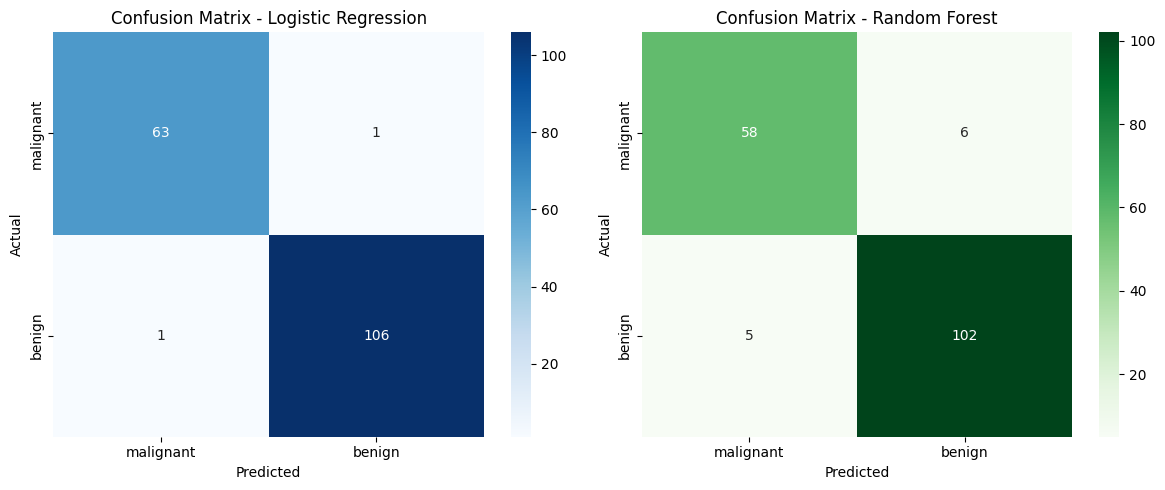

In [97]:
# Menghitung dan menampilkan dua confusion matrix
cm_logistic = confusion_matrix(y_test, y_pred_logistic, labels=[0, 1])
cm_rf = confusion_matrix(y_test, y_pred_rf, labels=[0, 1])

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.heatmap(
    cm_logistic, annot=True, fmt="d", cmap="Blues",
    xticklabels=["malignant", "benign"],
    yticklabels=["malignant", "benign"],
    ax=axes[0]
)
axes[0].set_title("Confusion Matrix - Logistic Regression")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")

sns.heatmap(
    cm_rf, annot=True, fmt="d", cmap="Greens",
    xticklabels=["malignant", "benign"],
    yticklabels=["malignant", "benign"],
    ax=axes[1]
)
axes[1].set_title("Confusion Matrix - Random Forest")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")

plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=200, bbox_inches="tight")
plt.show()

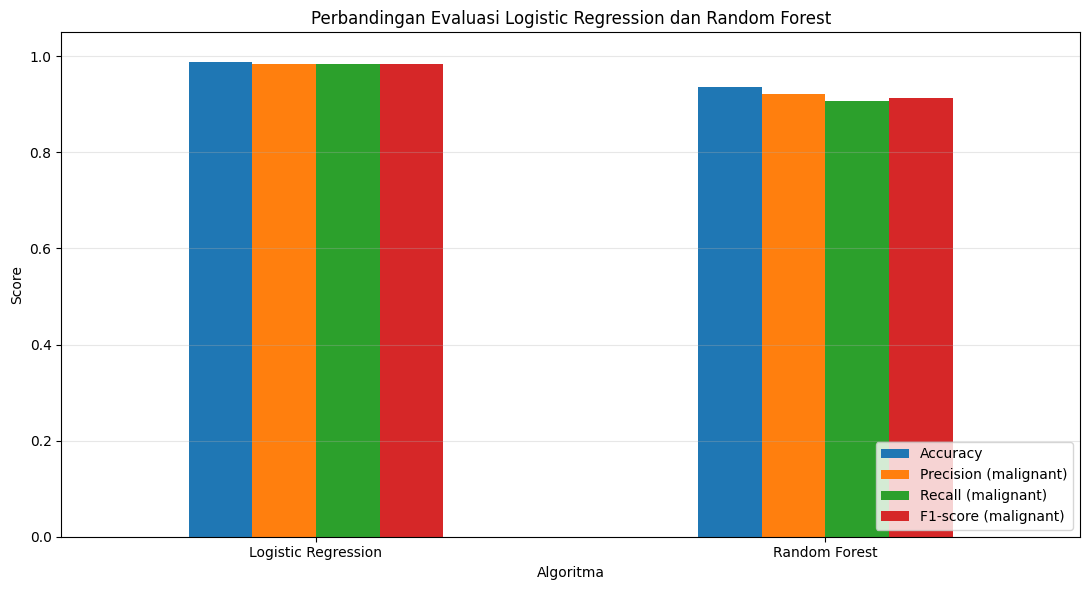

In [98]:
# Visualisasi perbandingan metrik
plot_data = evaluation_results.set_index("Algoritma")
plot_data.plot(kind="bar", figsize=(11, 6), ylim=(0, 1.05))
plt.title("Perbandingan Evaluasi Logistic Regression dan Random Forest")
plt.ylabel("Score")
plt.xlabel("Algoritma")
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig("evaluation_results.png", dpi=200, bbox_inches="tight")
plt.show()